In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.datasets import make_blobs
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Generate a synthetic customer dataset
X, _ = make_blobs(
    n_samples=300,
    centers=[
        [25, 25],
        [75, 80],
        [80, 25],
        [25, 80],
        [50, 50]
    ],
    cluster_std=8,
    random_state=42
)

# Create a DataFrame
df = pd.DataFrame(X, columns=[
    'Annual_Income',
    'Spending_Score'
])

# Convert values to realistic ranges
df['Annual_Income'] = df['Annual_Income'].clip(10, 150).round(2)
df['Spending_Score'] = df['Spending_Score'].clip(1, 100).round(2)

# Add customer IDs and age
np.random.seed(42)
df.insert(0, 'Customer_ID', range(1, len(df) + 1))
df['Age'] = np.random.randint(18, 65, size=len(df))

print("Generated Dataset:")
print(df.head(10))

print("\nDataset Shape:", df.shape)

# Save the generated dataset
df.to_csv("Generated_Customer_Dataset.csv", index=False)
print("\nDataset saved successfully!")

Generated Dataset:
   Customer_ID  Annual_Income  Spending_Score  Age
0            1          65.47           85.25   56
1            2          20.64           25.89   46
2            3          25.96           84.12   32
3            4          72.15           28.70   60
4            5          75.47           70.86   25
5            6          21.86           13.29   38
6            7          30.69           71.00   56
7            8          20.19           39.82   36
8            9          18.53           20.99   40
9           10          18.28           75.20   28

Dataset Shape: (300, 4)

Dataset saved successfully!


In [2]:
# Select features for clustering
features = df[['Annual_Income', 'Spending_Score']]

# Scale the features
scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

# K-Means
df['KMeans_Cluster'] = KMeans(
    n_clusters=5,
    random_state=42,
    n_init=10
).fit_predict(X_scaled)

# Agglomerative Clustering
df['Agglomerative_Cluster'] = AgglomerativeClustering(
    n_clusters=5
).fit_predict(X_scaled)

# DBSCAN
df['DBSCAN_Cluster'] = DBSCAN(
    eps=0.35,
    min_samples=5
).fit_predict(X_scaled)

print(df.head(10))

   Customer_ID  Annual_Income  Spending_Score  Age  KMeans_Cluster  \
0            1          65.47           85.25   56               3   
1            2          20.64           25.89   46               2   
2            3          25.96           84.12   32               0   
3            4          72.15           28.70   60               1   
4            5          75.47           70.86   25               3   
5            6          21.86           13.29   38               2   
6            7          30.69           71.00   56               0   
7            8          20.19           39.82   36               2   
8            9          18.53           20.99   40               2   
9           10          18.28           75.20   28               0   

   Agglomerative_Cluster  DBSCAN_Cluster  
0                      3               0  
1                      0               0  
2                      1               0  
3                      2               1  
4             

In [3]:
def evaluate_model(X, labels):
    # DBSCAN uses -1 to identify noise points
    valid = labels != -1
    X_valid = X[valid]
    labels_valid = labels[valid]

    n_clusters = len(set(labels_valid))

    if n_clusters < 2 or n_clusters >= len(labels_valid):
        return np.nan, np.nan

    silhouette = silhouette_score(X_valid, labels_valid)
    db_index = davies_bouldin_score(X_valid, labels_valid)

    return silhouette, db_index


algorithms = {
    'K-Means': df['KMeans_Cluster'].to_numpy(),
    'Agglomerative': df['Agglomerative_Cluster'].to_numpy(),
    'DBSCAN': df['DBSCAN_Cluster'].to_numpy()
}

results = []

for name, labels in algorithms.items():
    silhouette, db_index = evaluate_model(X_scaled, labels)

    results.append({
        'Algorithm': name,
        'Clusters': len(set(labels) - {-1}),
        'Silhouette Score': silhouette,
        'Davies-Bouldin Index': db_index
    })

results_df = pd.DataFrame(results)

print("\nClustering Performance:")
print(results_df.round(3).to_string(index=False))


Clustering Performance:
    Algorithm  Clusters  Silhouette Score  Davies-Bouldin Index
      K-Means         5             0.626                 0.496
Agglomerative         5             0.603                 0.507
       DBSCAN         2             0.377                 0.752


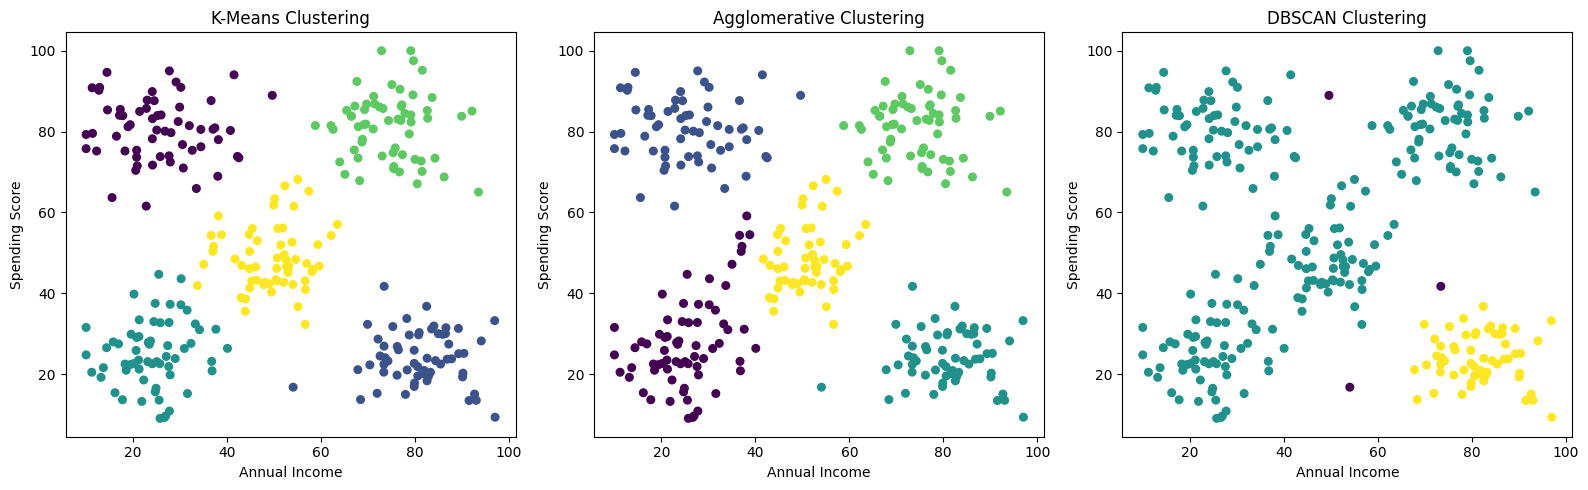

In [4]:
fig, axes = plt.subplots(1, 3, figsize=(16, 5))

cluster_columns = [
    'KMeans_Cluster',
    'Agglomerative_Cluster',
    'DBSCAN_Cluster'
]

titles = [
    'K-Means Clustering',
    'Agglomerative Clustering',
    'DBSCAN Clustering'
]

for ax, column, title in zip(axes, cluster_columns, titles):
    ax.scatter(
        df['Annual_Income'],
        df['Spending_Score'],
        c=df[column],
        cmap='viridis',
        s=30
    )

    ax.set_title(title)
    ax.set_xlabel('Annual Income')
    ax.set_ylabel('Spending Score')

plt.tight_layout()
plt.show()

In [5]:
print(df.head(20))

print("\nCustomers per K-Means cluster:")
print(df['KMeans_Cluster'].value_counts().sort_index())

print("\nFinal dataset saved as CSV.")

    Customer_ID  Annual_Income  Spending_Score  Age  KMeans_Cluster  \
0             1          65.47           85.25   56               3   
1             2          20.64           25.89   46               2   
2             3          25.96           84.12   32               0   
3             4          72.15           28.70   60               1   
4             5          75.47           70.86   25               3   
5             6          21.86           13.29   38               2   
6             7          30.69           71.00   56               0   
7             8          20.19           39.82   36               2   
8             9          18.53           20.99   40               2   
9            10          18.28           75.20   28               0   
10           11          33.25           32.45   28               2   
11           12          20.19           22.67   41               2   
12           13          56.64           32.31   53               4   
13    